# ECON 5200 Final Project — Milestone 1: Proposal + EDA
## Should Boston expand dorm capacity to lower neighborhood rents?
**Preliminary feasibility study | November 23, 2026**

This notebook follows Part 0 and Part 2 of the course starter. It reproduces the accompanying two-page proposal using the matched pilot data embedded below. The full IV design is proposed, not established. The pilot does not identify a causal effect.

## Part 0: Setup

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

RANDOM_STATE = 42                    # every split, fold and bootstrap uses this seed
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (9, 5)
print("Setup complete.")

Setup complete.


## Part 2: The Decision, the Design, and the Data
### Research design
- **Client and decision:** Boston Mayor's Office of Housing; decide whether to prioritize net new dorm beds in university housing negotiations.
- **Decides it:** A provisional decision target of at least $30 lower typical monthly rent near campus for 1,000 additional net dorm beds, specified before estimation; not an official cost-benefit rule.
- **Causal question:** Does dorm-induced reduction in off-campus undergraduate demand lower nearby market rents?
- **Why prediction is not enough:** Popular neighborhoods attract students and have higher rents. Amenities and student sorting confound comparisons across ZIPs.
- **Design and estimand:** Proposed 2SLS: local rent response to dorm-induced changes in off-campus undergraduates per 100 baseline renter households, conditional on ZIP/year fixed effects and predetermined enrollment. The pilot uses counts instead of density.
- **Who is treated:** One documented Berklee project, one host ZIP (02115), and two exposed ZIP-years in the pilot. The full design needs multiple independent bed shocks.
- **Comparison:** Within-ZIP changes against ZIPs with lower or no recorded exposure. Other ZIPs are not verified untreated controls.
- **Key assumption:** Preannounced net bed exposure is independent of other rent shocks conditional on controls and affects rents only through student density.
- **Check that could fail:** A negative, sufficiently strong first stage after controls; future bed plans should not predict earlier rent changes. The pilot cannot provide reliable shock-level inference.
- **Main threat:** A dorm conversion may remove private rental supply and increase rents directly; with a negative first stage, this would bias the density coefficient downward.

### Data provenance and pilot limitations
The embedded table is the matched, manually transcribed pilot dataset accompanying the proposal; the notebook reproduces its analysis without a network connection. It does not independently re-extract the PDF tables. Sources recorded for that dataset:
- [Boston Student Housing Report 2022, Table 11](https://content.boston.gov/sites/default/files/file/2023/06/Student%20Housing%20Report%2C%202022.pdf)
- [Boston Student Housing Report 2023, Table 11](https://www.boston.gov/sites/default/files/file/2024/06/Boston%20Student%20Housing%20Report_Final.pdf)
- [Boston Housing Report 2025, 2024 student housing data](https://www.boston.gov/sites/default/files/file/2025/06/Boston%20Housing%20Report%202025%20-%20Final%20Draft.pdf)
- [2025 Greater Boston Housing Report Card, pp. 93–94, annual published ZIP-level ZORI](https://www.bu.edu/ioc/files/2025/11/2025-Gr-Boston-Housing-Report-Card-Final-2025.pdf)
- [Berklee project planned opening and gross bed count](https://thebostonsun.com/2022/08/11/12-hemenway-st-only-project-included-in-latest-berklee-imp/) and [Berklee residence information](https://www.berklee.edu/housing-and-residential-education/12-hemenway-street).

**Full design still requires:** [ACS baseline renter households](https://data.census.gov/table/ACSDT5Y2017.B25003), [monthly ZORI](https://www.zillow.com/research/data/), verified cumulative net bed histories, project distances, and predetermined enrollment. Pilot rents are annual published values, not September–October averages. The pilot's 110 gross planned beds are not verified net additions. Baseline student counts are descriptive covariates, not enrollment controls.

In [2]:
# Load the data (embedded so the notebook also runs in Colab without a CSV upload).
from io import StringIO
PILOT_CSV = 'zip,year,undergraduates,graduates,rent,log_rent,host_zip,pilot_exposed,planned_gross_beds,actual_open_proxy,baseline_undergrads,baseline_grads\n02111,2022,330,555,3592.0,8.18646442942209,0,0,0,0,330,555\n02111,2023,316,528,3731.0,8.224431573221159,0,0,0,0,330,555\n02111,2024,265,519,3771.0,8.235095497258357,0,0,0,0,330,555\n02113,2022,193,160,2333.0,7.75491027202143,0,0,0,0,193,160\n02113,2023,191,155,2534.0,7.837554360881084,0,0,0,0,193,160\n02113,2024,114,163,2680.0,7.893572073504902,0,0,0,0,193,160\n02114,2022,289,555,3129.0,8.048468743668883,0,0,0,0,289,555\n02114,2023,305,499,3296.0,8.100464891029363,0,0,0,0,289,555\n02114,2024,235,465,3335.0,8.112227958349724,0,0,0,0,289,555\n02115,2022,3663,1610,2827.0,7.946971357693591,1,0,0,0,3663,1610\n02115,2023,3740,1271,3036.0,8.01829613851552,1,1,110,0,3663,1610\n02115,2024,3943,1122,3061.0,8.026496938945412,1,1,110,1,3663,1610\n02116,2022,382,605,3075.0,8.031060180240619,0,0,0,0,382,605\n02116,2023,393,538,3167.0,8.06054004653864,0,0,0,0,382,605\n02116,2024,370,517,3304.0,8.102889134640868,0,0,0,0,382,605\n02118,2022,662,1270,3243.0,8.084254106307318,0,0,0,0,662,1270\n02118,2023,838,1144,3466.0,8.150756470275551,0,0,0,0,662,1270\n02118,2024,851,1276,3511.0,8.163656176168432,0,0,0,0,662,1270\n02119,2022,479,824,2756.0,7.9215356321335495,0,0,0,0,479,824\n02119,2023,570,1333,2850.0,7.955074273262696,0,0,0,0,479,824\n02119,2024,575,1418,2991.0,8.003363058629947,0,0,0,0,479,824\n02120,2022,2287,1997,3548.0,8.17413934342947,0,0,0,0,2287,1997\n02120,2023,2709,1772,3439.0,8.142936010432265,0,0,0,0,2287,1997\n02120,2024,2797,1392,3744.0,8.227909837597483,0,0,0,0,2287,1997\n02122,2022,171,78,2606.0,7.8655717576847906,0,0,0,0,171,78\n02122,2023,208,73,2826.0,7.946617563244473,0,0,0,0,171,78\n02122,2024,210,103,2864.0,7.9599745280805365,0,0,0,0,171,78\n02124,2022,271,112,2544.0,7.841492924460013,0,0,0,0,271,112\n02124,2023,294,81,2715.0,7.906547232368036,0,0,0,0,271,112\n02124,2024,329,111,2813.0,7.9420068084898565,0,0,0,0,271,112\n02125,2022,873,821,2881.0,7.9658927350845286,0,0,0,0,873,821\n02125,2023,1031,1041,2986.0,8.001689978099135,0,0,0,0,873,821\n02125,2024,1055,1022,3065.0,8.027802848370312,0,0,0,0,873,821\n02127,2022,104,330,3199.0,8.070593539949519,0,0,0,0,104,330\n02127,2023,101,323,3433.0,8.141189793457691,0,0,0,0,104,330\n02127,2024,104,366,3398.0,8.130942302231878,0,0,0,0,104,330\n02128,2022,426,349,2677.0,7.892452043520352,0,0,0,0,426,349\n02128,2023,532,316,2830.0,7.948031990637284,0,0,0,0,426,349\n02128,2024,399,287,2928.0,7.982074875081202,0,0,0,0,426,349\n02130,2022,369,1322,2735.0,7.913886714856082,0,0,0,0,369,1322\n02130,2023,399,1648,2884.0,7.96693349840484,0,0,0,0,369,1322\n02130,2024,452,1685,3004.0,8.007700012884026,0,0,0,0,369,1322\n02131,2022,119,89,2365.0,7.768533300926033,0,0,0,0,119,89\n02131,2023,129,78,2565.0,7.84971375760487,0,0,0,0,119,89\n02131,2024,141,98,2646.0,7.880804344674901,0,0,0,0,119,89\n02134,2022,2310,2778,2647.0,7.881182202227102,0,0,0,0,2310,2778\n02134,2023,2036,2471,2866.0,7.960672608388117,0,0,0,0,2310,2778\n02134,2024,2051,2872,2886.0,7.9676267393338165,0,0,0,0,2310,2778\n02135,2022,2012,2605,2551.0,7.844240718141811,0,0,0,0,2012,2605\n02135,2023,2020,1829,2741.0,7.916078096302786,0,0,0,0,2012,2605\n02135,2024,1793,2658,2804.0,7.938802248154481,0,0,0,0,2012,2605\n02215,2022,2569,2347,2641.0,7.878912912297133,0,0,0,0,2569,2347\n02215,2023,2546,2021,2772.0,7.927324360309794,0,0,0,0,2569,2347\n02215,2024,2707,1963,2838.0,7.950854857719988,0,0,0,0,2569,2347\n'
df = pd.read_csv(StringIO(PILOT_CSV), dtype={"zip": str})
print("Shape:", df.shape)
print(df.head().to_string(index=False))

Shape: (54, 12)
  zip  year  undergraduates  graduates   rent  log_rent  host_zip  pilot_exposed  planned_gross_beds  actual_open_proxy  baseline_undergrads  baseline_grads
02111  2022             330        555 3592.0  8.186464         0              0                   0                  0                  330             555
02111  2023             316        528 3731.0  8.224432         0              0                   0                  0                  330             555
02111  2024             265        519 3771.0  8.235095         0              0                   0                  0                  330             555
02113  2022             193        160 2333.0  7.754910         0              0                   0                  0                  193             160
02113  2023             191        155 2534.0  7.837554         0              0                   0                  0                  193             160


In [3]:
# Missing values and sample rule
print("Missing values within the retained pilot:")
print(df.isna().sum().to_string())
print("Duplicate ZIP-year rows:", df.duplicated(["zip", "year"]).sum())
assert not df.duplicated(["zip", "year"]).any()
assert df[["undergraduates", "rent", "planned_gross_beds"]].notna().all().all()
assert (df.groupby("zip")["year"].nunique() == 3).all()
print("Retained ZIPs:", df.zip.nunique(), "| Years:", sorted(df.year.unique()), "| N:", len(df))
print("Host ZIPs:", df.loc[df.host_zip == 1, "zip"].nunique())
print("Exposed ZIP-years:", int(df.pilot_exposed.sum()))
print("Sample rule: retain matched ZIPs observed with student counts and rents in all three years.")
print("The embedded CSV is already matched; pre-merge counts and excluded ZIP identities are not available in this file.")

Missing values within the retained pilot:
zip                    0
year                   0
undergraduates         0
graduates              0
rent                   0
log_rent               0
host_zip               0
pilot_exposed          0
planned_gross_beds     0
actual_open_proxy      0
baseline_undergrads    0
baseline_grads         0
Duplicate ZIP-year rows: 0
Retained ZIPs: 18 | Years: [np.int64(2022), np.int64(2023), np.int64(2024)] | N: 54
Host ZIPs: 1
Exposed ZIP-years: 2
Sample rule: retain matched ZIPs observed with student counts and rents in all three years.
The embedded CSV is already matched; pre-merge counts and excluded ZIP identities are not available in this file.


In [4]:
def balance_table(data, group, cols):
    """Means by group, the difference, and the standardised difference (difference / pooled SD).

    group: a 0/1 column. For RD pass the rows inside your bandwidth, grouped by side of the cutoff;
    for DiD, the pre-period rows grouped by treated state; for IV, grouped by the instrument.
    A standardised difference above about 0.1 in absolute value is worth a sentence in the proposal.
    """
    g1, g0 = data[data[group] == 1], data[data[group] == 0]
    rows = []
    for c in cols:
        sd = np.sqrt((g1[c].var() + g0[c].var()) / 2)
        rows.append({"variable": c, "treated": g1[c].mean(), "comparison": g0[c].mean(),
                     "difference": g1[c].mean() - g0[c].mean(),
                     "std. difference": (g1[c].mean() - g0[c].mean()) / sd if sd > 0 else np.nan})
    out = pd.DataFrame(rows).set_index("variable")
    out.loc["N"] = [len(g1), len(g0), np.nan, np.nan]
    return out.round(3)



# Table 1: group by scheduled exposure, not verified treatment.
cols = ["rent", "undergraduates", "baseline_undergrads", "baseline_grads"]
balance = balance_table(df, "pilot_exposed", cols)
print(balance.to_string())
print("Comparison includes the host's pre-schedule year and other ZIP-years.")

                     treated  comparison  difference  std. difference
variable                                                             
rent                  3048.5    2981.385      67.115            0.260
undergraduates        3841.5     895.673    2945.827            4.344
baseline_undergrads   3663.0     869.250    2793.750            4.229
baseline_grads        1610.0    1000.019     609.981            0.968
N                        2.0      52.000         NaN              NaN
Comparison includes the host's pre-schedule year and other ZIP-years.


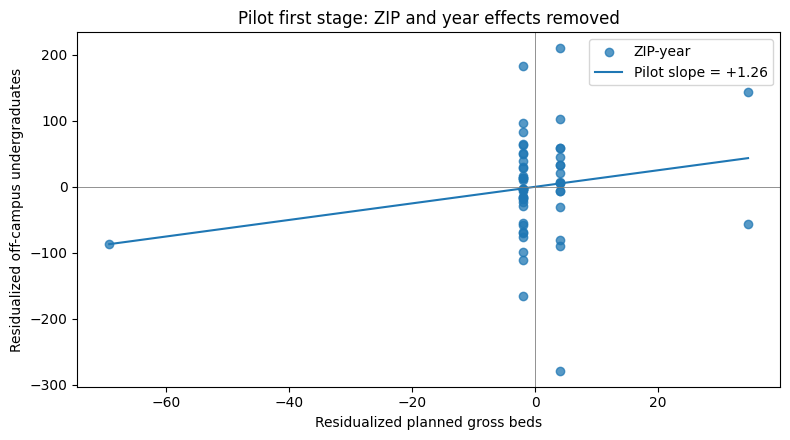

Pilot first-stage slope: +1.2553 students per gross bed
Conventional partial F (descriptive only): 1.2385
Expected sign: negative. Observed sign: positive.
One independent project shock; conventional F is not reliable evidence of IV strength.


In [5]:
# Figure 1: partial first stage after removing ZIP and year fixed effects.
# The full IV is not estimated: one project is insufficient for credible inference.
first = smf.ols("undergraduates ~ planned_gross_beds + C(zip) + C(year)", data=df).fit()
x = smf.ols("planned_gross_beds ~ C(zip) + C(year)", data=df).fit().resid
y = smf.ols("undergraduates ~ C(zip) + C(year)", data=df).fit().resid
slope = first.params["planned_gross_beds"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, alpha=0.75, label="ZIP-year")
xx = np.linspace(x.min(), x.max(), 100)
ax.plot(xx, slope * xx, label=f"Pilot slope = {slope:+.2f}")
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set(xlabel="Residualized planned gross beds", ylabel="Residualized off-campus undergraduates", title="Pilot first stage: ZIP and year effects removed")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Pilot first-stage slope: {slope:+.4f} students per gross bed")
print(f"Conventional partial F (descriptive only): {float(first.f_test('planned_gross_beds = 0').fvalue):.4f}")
print("Expected sign: negative. Observed sign: positive.")
print("One independent project shock; conventional F is not reliable evidence of IV strength.")

In [6]:
# Report numbers for the proposal
print("N:", len(df), "| ZIPs:", df.zip.nunique(), "| Exposed ZIP-years:", int(df.pilot_exposed.sum()))
print(balance[["treated", "comparison", "difference"]].round(1).to_string())
print("Host ZIP 02115:")
print(df.loc[df.host_zip.eq(1), ["zip", "year", "undergraduates", "planned_gross_beds", "actual_open_proxy"]].to_string(index=False))
print(f"First-stage slope: {slope:+.2f}")
print("Provisional decision threshold: $30/month per 1,000 net additional beds (not estimated).")

N: 54 | ZIPs: 18 | Exposed ZIP-years: 2
                     treated  comparison  difference
variable                                            
rent                  3048.5      2981.4        67.1
undergraduates        3841.5       895.7      2945.8
baseline_undergrads   3663.0       869.2      2793.8
baseline_grads        1610.0      1000.0       610.0
N                        2.0        52.0         NaN
Host ZIP 02115:
  zip  year  undergraduates  planned_gross_beds  actual_open_proxy
02115  2022            3663                   0                  0
02115  2023            3740                 110                  0
02115  2024            3943                 110                  1
First-stage slope: +1.26
Provisional decision threshold: $30/month per 1,000 net additional beds (not estimated).


**Key EDA finding:** The pilot slope is +1.26 students per gross bed, opposite the expected sign. Host ZIP 02115 rose from 3,663 to 3,943 off-campus undergraduates between 2022 and 2024.

**A concern:** Berklee planned 110 gross beds for fall 2023 but opened in spring 2024. Net additions and other projects are unverified. One project cannot support a credible IV estimate; other ZIPs may be exposed as well. The positive first-stage slope does not support the proposed displacement mechanism in this pilot.

**Next steps (Milestone 2):** Verify additional independent dorm projects and net bed counts, construct predetermined distance-weighted exposure and baseline renter denominators, obtain monthly rents and enrollment controls, check pre-trends and first-stage relevance, and only proceed to causal estimation if the evidence supports the design.